# Etapa 1 — Conhecer os dados

Objetivo: entender a base antes de qualquer modelo. Nenhum treinamento aqui.

Trabalho final PSI0325 — classificação de espécies de morcegos por descritores acústicos.

In [1]:
import pandas as pd

BANCO = "../banco/Cidade Viva e PELG Bioacústica (OFICIAL).xlsx - {}.csv"

## Carregando a aba Identificação (Cidade Viva + PELG)

Cada linha da Identificação é uma **gravação**: uma espécie, um conjunto de
descritores médios (Fmin, Fmax, Bandwidth, FME, Duração) e metadados de coleta.

In [2]:
ident_cv = pd.read_csv(BANCO.format("Cidade Viva - Identificação"))
ident_pelg = pd.read_csv(BANCO.format("PELG - Identificação"))

identificacao = pd.concat([ident_cv, ident_pelg], ignore_index=True)

print("Cidade Viva:", ident_cv.shape)
print("PELG:", ident_pelg.shape)
print("Total (Identificação):", identificacao.shape)
# Não exibimos linhas brutas: a base é pesquisa não publicada (só formas e contagens).

Cidade Viva: (9482, 40)
PELG: (5058, 39)
Total (Identificação): (14540, 41)


In [3]:
print("Colunas só em Cidade Viva:", set(ident_cv.columns) - set(ident_pelg.columns))
print("Colunas só em PELG:", set(ident_pelg.columns) - set(ident_cv.columns))

Colunas só em Cidade Viva: {'ARQUIVO', 'Unnamed: 39'}
Colunas só em PELG: {'Nome_arquivo'}


## Carregando a aba Valores (Cidade Viva + PELG) e entendendo o vínculo

Na aba Valores, cada linha é um **pulso individual** dentro de uma gravação (até
3 pulsos por gravação). A coluna `ARQUIVO` só vem preenchida na primeira linha de
cada gravação — as linhas seguintes ficam vazias e pertencem ao mesmo arquivo.

Por isso usamos `ffill` (*forward fill*): propaga o último valor não vazio de
`ARQUIVO` para baixo, até encontrar o próximo valor preenchido. Depois disso,
a coluna `ARQUIVO` da Valores casa exatamente com a coluna `Arquivo` da
Identificação, e é isso que liga as duas tabelas.

In [4]:
valores_cv = pd.read_csv(BANCO.format("Cidade Viva - Valores"))
valores_pelg = pd.read_csv(BANCO.format("PELG - Valores"))

valores = pd.concat([valores_cv, valores_pelg], ignore_index=True)

print("Antes do ffill, linhas com ARQUIVO vazio:", valores["ARQUIVO"].isna().sum(), "de", len(valores))

valores["ARQUIVO"] = valores["ARQUIVO"].ffill()

print("Depois do ffill, linhas com ARQUIVO vazio:", valores["ARQUIVO"].isna().sum())
print("Total (Valores, por pulso):", valores.shape)
print("Gravações distintas em Valores:", valores["ARQUIVO"].nunique())
print("Gravações distintas em Identificação:", identificacao["Arquivo"].nunique())

Antes do ffill, linhas com ARQUIVO vazio: 30252 de 44757
Depois do ffill, linhas com ARQUIVO vazio: 0
Total (Valores, por pulso): (44757, 15)
Gravações distintas em Valores: 14206
Gravações distintas em Identificação: 14202


In [5]:
arquivos_valores = set(valores["ARQUIVO"].dropna())
arquivos_ident = set(identificacao["Arquivo"].dropna())

# Só contagens: listar os nomes exporia dados brutos (base não publicada).
print("Em Valores mas não em Identificação:", len(arquivos_valores - arquivos_ident))
print("Em Identificação mas não em Valores:", len(arquivos_ident - arquivos_valores))

Em Valores mas não em Identificação: 90
Em Identificação mas não em Valores: 86


## Limpando a chave de junção

Não existe uma chave primária limpa em comum entre as duas abas: o nome do
arquivo é a chave pretendida, mas foi digitado de formas diferentes em cada
planilha (espaços sobrando, `_000` presente ou não, `_` no lugar de espaço na
anotação de espécie). A parte que realmente identifica a gravação é o trecho
antes do parêntese com o nome da espécie — é nele que vamos normalizar.

In [6]:
import re


def normaliza_arquivo(nome):
    if pd.isna(nome):
        return nome
    nome = nome.strip()
    nome = nome.split("(")[0].strip()
    nome = re.sub(r"_000$", "", nome)
    return nome


identificacao["Arquivo_norm"] = identificacao["Arquivo"].apply(normaliza_arquivo)
valores["Arquivo_norm"] = valores["ARQUIVO"].apply(normaliza_arquivo)

arquivos_valores_norm = set(valores["Arquivo_norm"].dropna())
arquivos_ident_norm = set(identificacao["Arquivo_norm"].dropna())

print("Gravações distintas em Valores (normalizado):", len(arquivos_valores_norm))
print("Gravações distintas em Identificação (normalizado):", len(arquivos_ident_norm))
print("Em Valores mas não em Identificação:", len(arquivos_valores_norm - arquivos_ident_norm))
print("Em Identificação mas não em Valores:", len(arquivos_ident_norm - arquivos_valores_norm))
# Os nomes que ficam sem par não são listados (base não publicada).

Gravações distintas em Valores (normalizado): 14159
Gravações distintas em Identificação (normalizado): 14159
Em Valores mas não em Identificação: 24
Em Identificação mas não em Valores: 24


## Gravações por espécie

Contagem direto na aba Identificação (uma linha = uma gravação), sem ainda
juntar com Valores — para conferir os números do plano: 14.540 gravações,
22 espécies, 8 espécies com ≥ 379 gravações.

In [7]:
contagem_especies = identificacao["Espécie/Sonótipo"].value_counts()

print("Total de gravações:", len(identificacao))
print("Número de espécies/sonótipos distintos:", contagem_especies.shape[0])
print()
print("Espécies com >= 379 gravações:", (contagem_especies >= 379).sum())
print()
contagem_especies

Total de gravações: 14540
Número de espécies/sonótipos distintos: 23

Espécies com >= 379 gravações: 8



Espécie/Sonótipo
Myotis_lavali                7303
Molossus_molossus            1653
Lasiurus_blossevillii        1083
Neoeptesicus_furinalis       1014
Eumops_sp                     729
Molossus_currentium           717
Molossops_temminckii          557
Myotis_nigricans              384
Molossidae1                   358
Peropteryx_trinitatis         248
Molossops_neglectus           118
Neoeptesicus_brasiliensis      99
Molossus_spp                   82
Peropteryx_macrotis            77
Lasiurus_ega_egregius          19
Eumops_perotis                 19
Cynomops_planirostris          15
Myotis_riparius                 9
Lasiurus_villosissimus          3
Histiotus_velatus               2
Myotis_sp1                      2
Peropteryx_kappleri             1
Noctilio_albiventris            1
Name: count, dtype: int64

`Molossidae1` não é uma espécie (é um sonótipo indefinido de família, ver
`DIARIO.md`). Excluída da lista — e não faz diferença no recorte de 8 espécies,
já que suas 358 gravações já ficam abaixo do corte de 379.

In [8]:
contagem_especies = contagem_especies.drop("Molossidae1")
especies_recorte = contagem_especies[contagem_especies >= 379].index.tolist()

print("Espécies no recorte:", len(especies_recorte))
for esp in especies_recorte:
    print(f"  {esp}: {contagem_especies[esp]}")

Espécies no recorte: 8
  Myotis_lavali: 7303
  Molossus_molossus: 1653
  Lasiurus_blossevillii: 1083
  Neoeptesicus_furinalis: 1014
  Eumops_sp: 729
  Molossus_currentium: 717
  Molossops_temminckii: 557
  Myotis_nigricans: 384


## Valores faltantes por coluna

Olhando só as gravações do recorte de 8 espécies, que é o que de fato vamos
usar dali pra frente.

In [9]:
ident_recorte = identificacao[identificacao["Espécie/Sonótipo"].isin(especies_recorte)].copy()

print("Gravações no recorte:", len(ident_recorte))
print()

faltantes = ident_recorte.isna().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)
faltantes_pct = (faltantes / len(ident_recorte) * 100).round(1)

pd.DataFrame({"faltantes": faltantes, "pct": faltantes_pct})

Gravações no recorte: 13440



,faltantes,pct
ARQUIVO,13440,100.0
Nome_arquivo,13440,100.0
Unnamed: 39,13440,100.0
Sonograma,11655,86.7
Tem_outra_espécie,3379,25.1
Obs,3378,25.1
Modelo_gravador,8,0.1
Estação,2,0.0
Família,2,0.0
Subfamília,2,0.0


## Histograma de FME por espécie

Um painel por espécie (mesmo eixo X em todos), para enxergar onde as faixas de
frequência se sobrepõem. Com 8 espécies, sobrepor tudo num único histograma
colorido ficaria ilegível — separar em painéis com eixo alinhado mostra a
mesma sobreposição de forma mais clara.

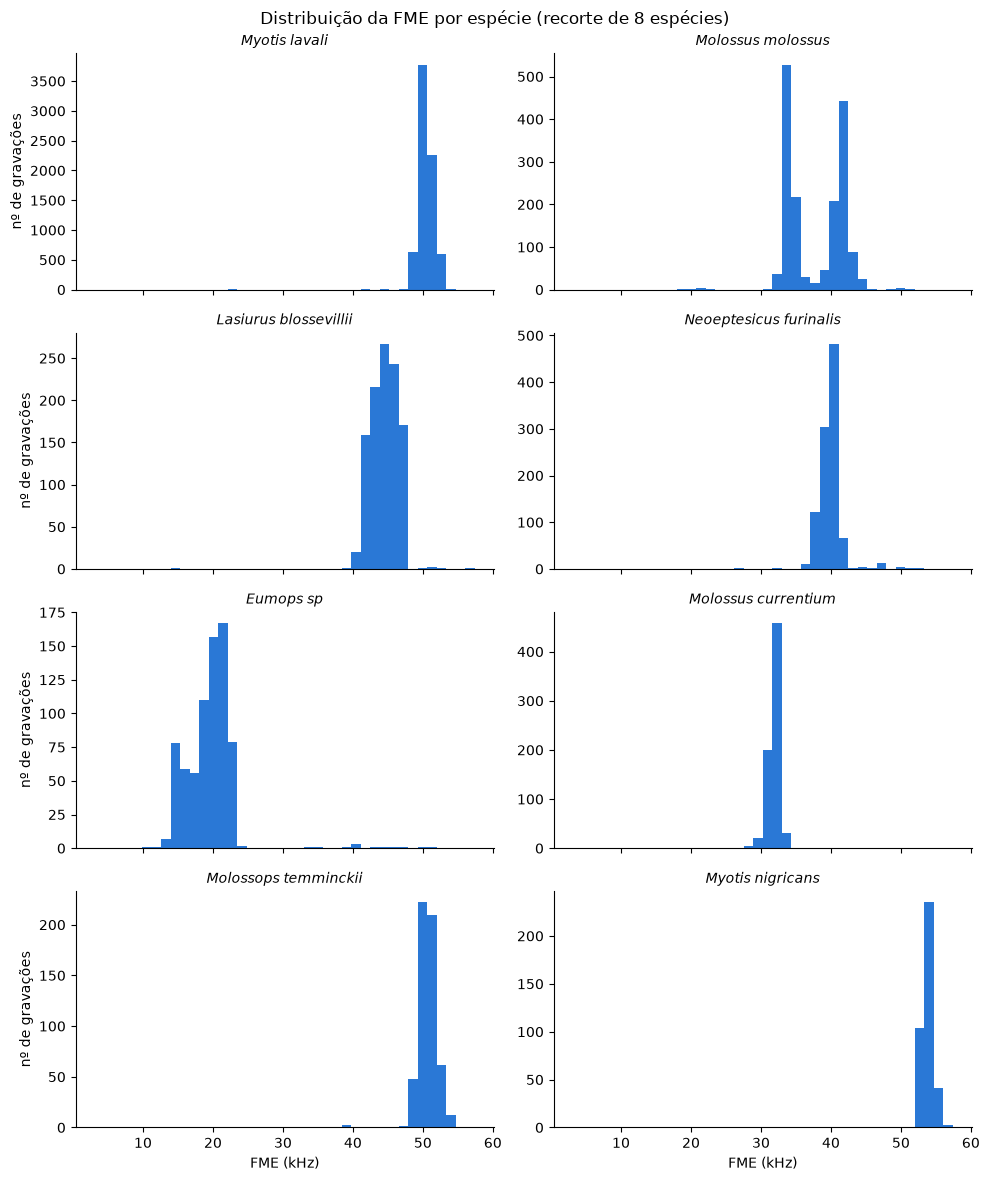

In [10]:
import matplotlib.pyplot as plt

COR = "#2a78d6"
COL_FME = "FME (kHz)"

fme_min, fme_max = ident_recorte[COL_FME].min(), ident_recorte[COL_FME].max()
bins = 40

fig, axes = plt.subplots(4, 2, figsize=(10, 12), sharex=True)

for ax, especie in zip(axes.flat, especies_recorte):
    valores_especie = ident_recorte.loc[ident_recorte["Espécie/Sonótipo"] == especie, COL_FME]
    ax.hist(valores_especie, bins=bins, range=(fme_min, fme_max), color=COR)
    ax.set_title(especie.replace("_", " "), fontsize=10, style="italic")
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[-1]:
    ax.set_xlabel("FME (kHz)")
for ax in axes[:, 0]:
    ax.set_ylabel("nº de gravações")

fig.suptitle("Distribuição da FME por espécie (recorte de 8 espécies)")
fig.tight_layout()
plt.show()

## Comparando com a Chave dos especialistas

A aba Chave é a referência que os próprios especialistas usam pra identificar
as espécies no campo — inclui a faixa de FME esperada por espécie. Comparamos
com o que os dados mostram.

In [11]:
chave = pd.read_csv(BANCO.format("Chave"))
chave["Família"] = chave["Família"].ffill()

# "Eumops sp" (dados) x "Eumops sp." (Chave, com ponto) — mesma espécie, grafia diferente
especies_nome_chave = [e.replace("_", " ") for e in especies_recorte]
especies_nome_chave = [n + "." if n == "Eumops sp" else n for n in especies_nome_chave]

chave_recorte = chave[chave["Espécie"].isin(especies_nome_chave)]
chave_recorte[["Família", "Espécie", "FME(kHz)"]]

,Família,Espécie,FME(kHz)
0,Molossidae,Molossops temminckii,50 kHz
2,Molossidae,Molossus currentium,FME1 ≈ 30 kHz; FME2 ≈ 33kHz; FME3 ≈ 36kHz
4,Molossidae,Molossus molossus,FME1 ≈ 34 (33-35) kHz; FME2 ≈ ...
6,Molossidae,Eumops sp.,≤18 kHz
8,Vespertilionidae,Neoeptesicus furinalis,≈ 39 (37-41) kHz
10,Vespertilionidae,Myotis lavali,49-52 kHz
11,Vespertilionidae,Myotis nigricans,52-55 kHz
13,Vespertilionidae,Lasiurus blossevillii,≈ 46 (38-45) kHz


In [12]:
resumo_fme = ident_recorte.groupby("Espécie/Sonótipo")[COL_FME].describe()[["min", "25%", "50%", "75%", "max"]]
resumo_fme.round(1)

,min,25%,50%,75%,max
Espécie/Sonótipo,,,,,
Eumops_sp,10.5,17.5,20.0,21.2,51.4
Lasiurus_blossevillii,14.6,43.1,44.6,46.1,57.4
Molossops_temminckii,38.5,49.7,50.6,51.3,54.0
Molossus_currentium,23.7,31.4,32.1,32.6,37.2
Molossus_molossus,18.4,33.8,37.9,41.4,51.7
Myotis_lavali,3.1,49.6,50.2,51.0,55.3
Myotis_nigricans,51.7,53.2,53.7,54.0,56.5
Neoeptesicus_furinalis,27.4,39.1,40.0,40.6,52.7


### Investigando os extremos

`Myotis lavali` tem uma gravação com FME de 3,1 kHz (esperado: 49-52) e
`Eumops sp` tem uma com FME de 51,4 kHz (esperado: ≤18). Olhando as outras
colunas da mesma gravação para entender o que houve.

In [13]:
cols_relevantes = ["Espécie/Sonótipo", "Tipo_pulso", "Fmin (kHz)", "Fmax (kHz)",
                   "Bandwidth (kHz)", "FME (kHz)", "Duração (ms)", "N_pulsos"]  # sem o nome do arquivo

linha_lavali = ident_recorte[(ident_recorte["Espécie/Sonótipo"] == "Myotis_lavali") & (ident_recorte[COL_FME] < 10)]
linha_eumops = ident_recorte[(ident_recorte["Espécie/Sonótipo"] == "Eumops_sp") & (ident_recorte[COL_FME] > 45)]

print("Myotis lavali com FME baixa:")
display(linha_lavali[cols_relevantes])
print("\nEumops sp com FME alta:")
display(linha_eumops[cols_relevantes])

Myotis lavali com FME baixa:


,Espécie/Sonótipo,Tipo_pulso,Fmin (kHz),Fmax (kHz),Bandwidth (kHz),FME (kHz),Duração (ms),N_pulsos
12509,Myotis_lavali,FMd/qCFd,69.496,50.25,85.120,3.09,20.755,45.0



Eumops sp com FME alta:


,Espécie/Sonótipo,Tipo_pulso,Fmin (kHz),Fmax (kHz),Bandwidth (kHz),FME (kHz),Duração (ms),N_pulsos
6081,Eumops_sp,qCFd,41.607,73.375,31.768,46.558,2.490,17.0
9490,Eumops_sp,qCFd,48.785,67.075,18.290,49.570,3.149,10.0
11157,Eumops_sp,qCFd,44.781,46.337,1.556,45.460,3.161,33.0
12418,Eumops_sp,qCFd,50.008,72.984,22.977,51.412,4.289,34.0


### Checando todas as 8 espécies: nome do arquivo (anotação manual) x rótulo oficial

O nome do arquivo costuma trazer a espécie que a pessoa anotou na hora da
gravação, entre parênteses. Comparamos essa anotação com o rótulo oficial da
coluna `Espécie/Sonótipo` para todo o recorte, não só para os dois casos
extremos que apareceram por acaso.

In [14]:
def extrai_anotacao(arquivo):
    m = re.search(r"\((.*?)\)", str(arquivo))
    if not m:
        return None
    return m.group(1).strip().lower().replace("_", " ")


def normaliza_rotulo(rotulo):
    return rotulo.strip().lower().replace("_", " ")


ident_recorte["anotacao_arquivo"] = ident_recorte["Arquivo"].apply(extrai_anotacao)
ident_recorte["rotulo_norm"] = ident_recorte["Espécie/Sonótipo"].apply(normaliza_rotulo)

com_anotacao = ident_recorte.dropna(subset=["anotacao_arquivo"])
# só considera "divergente" quando o rótulo oficial não aparece nem como substring da anotação
divergentes = com_anotacao[
    ~com_anotacao.apply(lambda r: r["rotulo_norm"] in r["anotacao_arquivo"] or r["anotacao_arquivo"] in r["rotulo_norm"], axis=1)
]

print("Gravações com anotação no arquivo:", len(com_anotacao))
print("Divergências (rótulo oficial não aparece na anotação do arquivo):", len(divergentes))
print()
print(divergentes.groupby("Espécie/Sonótipo").size())

Gravações com anotação no arquivo: 13433
Divergências (rótulo oficial não aparece na anotação do arquivo): 159

Espécie/Sonótipo
Eumops_sp                 12
Lasiurus_blossevillii      6
Molossops_temminckii      30
Molossus_currentium       15
Molossus_molossus         25
Myotis_lavali             34
Myotis_nigricans           3
Neoeptesicus_furinalis    34
dtype: int64


In [15]:
# Amostra de linhas brutas removida (o nome do arquivo é dado não publicado): só a contagem.
print("Divergências por espécie oficial:")
print(divergentes["Espécie/Sonótipo"].value_counts())

Divergências por espécie oficial:
Espécie/Sonótipo
Neoeptesicus_furinalis    34
Myotis_lavali             34
Molossops_temminckii      30
Molossus_molossus         25
Molossus_currentium       15
Eumops_sp                 12
Lasiurus_blossevillii      6
Myotis_nigricans           3
Name: count, dtype: int64


### Descartando as 5 linhas confirmadas como erro grave

1 gravação de `Myotis lavali` com `Fmin > Fmax` (medição corrompida) e 4
gravações de `Eumops sp` cujo nome de arquivo indica espécie totalmente
diferente da rotulada. As demais divergências entre nome de arquivo e rótulo
(majoritariamente erro de digitação no nome do arquivo, não no rótulo) ficam
como limitação documentada, não removidas — ver `DIARIO.md`.

In [16]:
indices_descartar = pd.concat([linha_lavali, linha_eumops]).index

print("Linhas antes do descarte:", len(ident_recorte))
ident_recorte = ident_recorte.drop(index=indices_descartar)
print("Linhas depois do descarte:", len(ident_recorte))

Linhas antes do descarte: 13440
Linhas depois do descarte: 13435


## Investigando Fstart/Fend

Pendência registrada no `PLANO.md`: disseram que são a frequência no início e
no fim do chamado, mas há suspeita de que sejam as bordas da caixa de seleção
do software de análise (artefato de interface), não uma medida acústica real.
Três verificações:

1. Ficam fora de `[Fmin, Fmax]`?
2. Variam muito em chamados quase constantes (`qCFd`)?
3. São múltiplos de 0,32 kHz?

In [17]:
print("Nomes de coluna (conferindo Fstart/Fend):")
print([c for c in ident_recorte.columns if "start" in c.lower() or "end" in c.lower()])

col_fstart, col_fend = "Fstart(s)", "Fend(s)"
col_fmin, col_fmax = "Fmin (kHz)", "Fmax (kHz)"

fora_1 = (ident_recorte[col_fstart] < ident_recorte[col_fmin]) | (ident_recorte[col_fstart] > ident_recorte[col_fmax])
fora_2 = (ident_recorte[col_fend] < ident_recorte[col_fmin]) | (ident_recorte[col_fend] > ident_recorte[col_fmax])
fora = fora_1 | fora_2

print(f"\n1) Fstart ou Fend fora de [Fmin, Fmax]: {fora.sum()} de {len(ident_recorte)} ({fora.mean()*100:.1f}%)")

Nomes de coluna (conferindo Fstart/Fend):
['Fstart(s)', 'Fend(s)']

1) Fstart ou Fend fora de [Fmin, Fmax]: 13435 de 13435 (100.0%)


In [18]:
print("Valores distintos de Tipo_pulso:", ident_recorte["Tipo_pulso"].unique())

qcfd = ident_recorte[ident_recorte["Tipo_pulso"].str.contains("qCFd", na=False)]
print(f"\nGravações qCFd: {len(qcfd)}")

# comparação correta: desvio-padrão DENTRO de cada espécie (não misturando espécies)
desvio_por_especie = qcfd.groupby("Espécie/Sonótipo")[[col_fstart, col_fend, COL_FME]].std()
desvio_por_especie.columns = ["Fstart", "Fend", "FME"]
desvio_por_especie.round(1)

Valores distintos de Tipo_pulso: <StringArray>
['FMa/qCF', 'FMd/qCFd', 'FMa/qCFd', 'qCFd']
Length: 4, dtype: str

Gravações qCFd: 12878


,Fstart,Fend,FME
Espécie/Sonótipo,,,
Eumops_sp,3.1,5.7,3.3
Lasiurus_blossevillii,3.7,9.6,2.1
Molossus_currentium,2.9,4.5,1.0
Molossus_molossus,5.2,8.0,4.1
Myotis_lavali,3.0,9.3,1.5
Myotis_nigricans,2.8,6.5,0.8
Neoeptesicus_furinalis,3.1,9.4,1.7


In [19]:
def eh_multiplo(valores, passo=0.32, tolerancia=1e-2):
    razao = valores / passo
    return (abs(razao - razao.round()) < tolerancia)

mult_fstart = eh_multiplo(ident_recorte[col_fstart])
mult_fend = eh_multiplo(ident_recorte[col_fend])
mult_fmin = eh_multiplo(ident_recorte[col_fmin])

print(f"3) Fstart múltiplo de 0,32 kHz: {mult_fstart.mean()*100:.1f}%")
print(f"   Fend múltiplo de 0,32 kHz:   {mult_fend.mean()*100:.1f}%")
print(f"   (comparação) Fmin múltiplo de 0,32 kHz: {mult_fmin.mean()*100:.1f}%")

3) Fstart múltiplo de 0,32 kHz: 77.7%
   Fend múltiplo de 0,32 kHz:   77.7%
   (comparação) Fmin múltiplo de 0,32 kHz: 2.3%


## Investigando Bandwidth

Pendência do plano: verificar em quantos pulsos `Bandwidth = Fmax − Fmin`, o
que tornaria a coluna redundante. Isso é por pulso individual, então usamos a
aba Valores (não a Identificação), filtrada para as gravações do recorte de 8
espécies pela chave normalizada.

In [20]:
print("Colunas da aba Valores:", list(valores.columns))

arquivos_recorte_norm = set(ident_recorte["Arquivo_norm"])
valores_recorte = valores[valores["Arquivo_norm"].isin(arquivos_recorte_norm)].copy()

print("\nPulsos no recorte de 8 espécies:", len(valores_recorte))

Colunas da aba Valores: ['ARQUIVO', 'Fstart(s)', 'Fend(s)', 'Fmin(kHz)', 'Fmax(kHz)', 'Bandwidth (kHz)', 'FME(kHz)', 'Dur(ms)', 'MediaFstart', 'MediaFend', 'MediaFmin', 'MediaFmax', 'MediaBW', 'MediaFME', 'MediaDur', 'Arquivo_norm']

Pulsos no recorte de 8 espécies: 41820


In [21]:
colunas_numericas = ["Fstart(s)", "Fend(s)", "Fmin(kHz)", "Fmax(kHz)", "Bandwidth (kHz)",
                     "FME(kHz)", "Dur(ms)", "MediaFstart", "MediaFend", "MediaFmin",
                     "MediaFmax", "MediaBW", "MediaFME", "MediaDur"]

for col in colunas_numericas:
    valores_recorte[col] = pd.to_numeric(
        valores_recorte[col].astype(str).str.replace(",", ".", regex=False), errors="coerce"
    )

print(valores_recorte[colunas_numericas].isna().sum())

Fstart(s)           1229
Fend(s)             1228
Fmin(kHz)           1224
Fmax(kHz)           1224
Bandwidth (kHz)        0
FME(kHz)            1226
Dur(ms)             1227
MediaFstart        28288
MediaFend          28288
MediaFmin          28288
MediaFmax          28288
MediaBW            27880
MediaFME           28288
MediaDur           28288
dtype: int64


In [22]:
bw_calculado = valores_recorte["Fmax(kHz)"] - valores_recorte["Fmin(kHz)"]
diferenca = (valores_recorte["Bandwidth (kHz)"] - bw_calculado).abs()

bate = diferenca < 1e-2  # tolerância de arredondamento

print(f"Bandwidth == Fmax - Fmin: {bate.sum()} de {len(valores_recorte)} pulsos ({bate.mean()*100:.1f}%)")
print(f"\nNos que não batem, diferença (Bandwidth - (Fmax-Fmin)):")
diferenca[~bate].describe()

Bandwidth == Fmax - Fmin: 38250 de 41820 pulsos (91.5%)

Nos que não batem, diferença (Bandwidth - (Fmax-Fmin)):


count    2346.000000
mean      734.083698
std       188.511450
min         1.724000
25%       618.880500
50%       774.225000
75%       876.123000
max       998.001000
dtype: float64

In [23]:
valores_recorte.loc[~bate, ["Fmin(kHz)", "Fmax(kHz)", "Bandwidth (kHz)"]].sort_values(
    "Bandwidth (kHz)", ascending=False
).head(10)

,Fmin(kHz),Fmax(kHz),Bandwidth (kHz)
35575,33.336,34.335,999.0
32209,33.336,34.335,999.0
33521,33.336,34.335,999.0
36461,19.178,20.177,999.0
31747,33.336,34.335,999.0
20251,33.785,34.783,998.0
18933,13.629,14.626,997.0
16307,31.525,32.522,997.0
18286,14.599,15.595,996.0
13449,15.535,16.531,996.0


In [24]:
# hipótese: Bandwidth >= 900 é um código de "sem valor" (sentinela), não medição real
sentinela = valores_recorte["Bandwidth (kHz)"] >= 900

print(f"Bandwidth >= 900 (sentinela suspeito): {sentinela.sum()} pulsos")
print(f"Do total de {(~bate).sum()} que não batiam com Fmax-Fmin")
print()
print("Valores únicos de Bandwidth >= 900:", sorted(valores_recorte.loc[sentinela, 'Bandwidth (kHz)'].unique())[:15])

Bandwidth >= 900 (sentinela suspeito): 471 pulsos
Do total de 3570 que não batiam com Fmax-Fmin

Valores únicos de Bandwidth >= 900: [np.float64(900.0), np.float64(901.0), np.float64(902.0), np.float64(903.0), np.float64(904.0), np.float64(905.0), np.float64(906.0), np.float64(907.0), np.float64(908.0), np.float64(909.0), np.float64(910.0), np.float64(911.0), np.float64(912.0), np.float64(913.0), np.float64(914.0)]


In [25]:
resto = (~bate) & (~sentinela) & diferenca.notna()
print(f"Diferenças 'pequenas' restantes (nem sentinela, nem NaN): {resto.sum()}")
diferenca[resto].describe()

Diferenças 'pequenas' restantes (nem sentinela, nem NaN): 1875


count    1875.000000
mean      679.577227
std       171.718889
min         1.724000
25%       574.425000
50%       703.296000
75%       833.166000
max       952.047000
dtype: float64

In [26]:
print("Distribuição de Bandwidth (kHz) para os que NÃO batem com Fmax-Fmin:")
print(valores_recorte.loc[~bate & diferenca.notna(), "Bandwidth (kHz)"].describe())
print()
print("Contagem por faixa:")
bw_resto = valores_recorte.loc[~bate & diferenca.notna(), "Bandwidth (kHz)"]
print(pd.cut(bw_resto, bins=[0, 20, 100, 500, 900, 1000]).value_counts().sort_index())

Distribuição de Bandwidth (kHz) para os que NÃO batem com Fmax-Fmin:
count    2346.000000
mean      732.771201
std       196.510178
min      -953.000000
25%       619.000000
50%       774.500000
75%       877.000000
max       999.000000
Name: Bandwidth (kHz), dtype: float64

Contagem por faixa:
Bandwidth (kHz)
(0, 20]           2
(20, 100]         3
(100, 500]      305
(500, 900]     1563
(900, 1000]     470
Name: count, dtype: int64


## Visualizando as espécies em 2D com PCA

Implementado do zero com NumPy, a partir das fórmulas dos slides — sem
scikit-learn. Passos: padronizar (média zero, variância unitária), calcular a
matriz de covariância, decompor em autovalores/autovetores, projetar nos 2
componentes de maior variância.

Usando a representação simples (Fmin, Fmax, Bandwidth, FME, Duração), a mesma
que vamos usar nas Etapas A e B. `Bandwidth` é recalculado como `Fmax - Fmin`
(decisão registrada no `DIARIO.md`), não a coluna original da planilha.

In [27]:
import numpy as np

col_dur = "Duração (ms)"

X = np.column_stack([
    ident_recorte[col_fmin].to_numpy(),
    ident_recorte[col_fmax].to_numpy(),
    (ident_recorte[col_fmax] - ident_recorte[col_fmin]).to_numpy(),  # Bandwidth recalculado
    ident_recorte[COL_FME].to_numpy(),
    ident_recorte[col_dur].to_numpy(),
])
nomes_features = ["Fmin", "Fmax", "Bandwidth", "FME", "Duração"]
rotulos = ident_recorte["Espécie/Sonótipo"].to_numpy()

print("X shape:", X.shape)
print("Algum NaN em X?", np.isnan(X).any())

X shape: (13435, 5)
Algum NaN em X? False


In [28]:
# padronização: média zero, variância unitária (Slides_5) — sem essa etapa, Duração
# (escala de ms, valores ~1-20) dominaria a variância só por causa da escala, não
# por ser mais informativa que Fmin/Fmax/FME (escala de kHz, valores ~10-60)
media = X.mean(axis=0)
desvio = X.std(axis=0)
X_padronizado = (X - media) / desvio

print("Média após padronização (deve ser ~0):", X_padronizado.mean(axis=0).round(3))
print("Desvio após padronização (deve ser ~1):", X_padronizado.std(axis=0).round(3))

Média após padronização (deve ser ~0): [-0. -0.  0. -0. -0.]
Desvio após padronização (deve ser ~1): [1. 1. 1. 1. 1.]


In [29]:
# matriz de covariância S = (1/N) Σ (x - x̄)(x - x̄)ᵀ, como no slide de PCA (divide por N,
# não por N-1: por isso bias=True). Uma linha/coluna por feature (5x5).
cov = np.cov(X_padronizado, rowvar=False, bias=True)

# autovalores e autovetores — eigh porque cov é simétrica (mais estável e já
# devolve em ordem crescente)
autovalores, autovetores = np.linalg.eigh(cov)

# eigh devolve em ordem crescente; queremos do maior pro menor
ordem = np.argsort(autovalores)[::-1]
autovalores = autovalores[ordem]
autovetores = autovetores[:, ordem]

# % da variância explicada por componente = 100 λ_l / Σ λ_k (slide de PCA)
variancia_explicada = autovalores / autovalores.sum()
print("Variância explicada por componente:")
for i, v in enumerate(variancia_explicada):
    print(f"  PC{i+1}: {v*100:.1f}%")
print(f"\nPC1 + PC2 juntos: {variancia_explicada[:2].sum()*100:.1f}% da variância total")
print("(o slide sugere ficar com componentes que somem em torno de 80% da variância)")

Variância explicada por componente:
  PC1: 69.7%
  PC2: 19.0%
  PC3: 11.0%
  PC4: 0.2%
  PC5: -0.0%

PC1 + PC2 juntos: 88.7% da variância total
(o slide sugere ficar com componentes que somem em torno de 80% da variância)


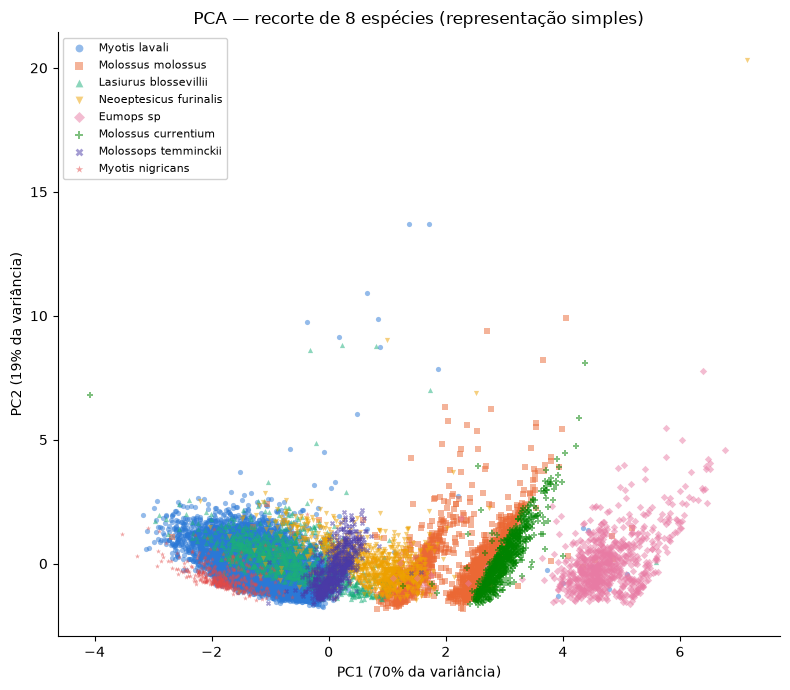

In [30]:
componentes_pca = autovetores[:, :2]
X_pca = X_padronizado @ componentes_pca

PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
MARCADORES = ["o", "s", "^", "v", "D", "P", "X", "*"]

fig, ax = plt.subplots(figsize=(8, 7))
for cor, marcador, especie in zip(PALETA, MARCADORES, especies_recorte):
    mask = rotulos == especie
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=14, alpha=0.5, color=cor,
               marker=marcador, label=especie.replace("_", " "), linewidths=0)

ax.set_xlabel(f"PC1 ({variancia_explicada[0]*100:.0f}% da variância)")
ax.set_ylabel(f"PC2 ({variancia_explicada[1]*100:.0f}% da variância)")
ax.set_title("PCA — recorte de 8 espécies (representação simples)")
ax.legend(fontsize=8, markerscale=1.5, framealpha=0.9)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Visualizando as espécies em 2D com LDA

LDA é supervisionado: usa o rótulo de espécie para achar as direções que
**maximizam a separação entre classes** (ao contrário do PCA, que não olha
pro rótulo). A ideia (slide de LDA): maximizar a dispersão *entre* as médias das
classes em relação à dispersão *dentro* de cada classe.

Fórmulas do slide, com `m_k` a média da classe k, `m` a média global e `N_k` o
tamanho da classe:

- `S_B = Σ_k N_k (m_k − m)(m_k − m)ᵀ` (entre classes)
- `S_W = Σ_k Σ_{x ∈ D_k} (x − m_k)(x − m_k)ᵀ` (dentro das classes)
- as direções são os autovetores de `S_W⁻¹ S_B` com autovalores não nulos.

**Cuidado com a inversa.** O slide usa `S_W⁻¹`, que só existe se `S_W` tiver posto
cheio. Aqui `Bandwidth = Fmax − Fmin` exatamente, então `S_W` com as 5 colunas
seria singular. Em vez de recorrer a uma pseudo-inversa (que não está nos slides),
o LDA usa só as **4 colunas independentes** (Fmin, Fmax, FME, Duração). Além disso,
o slide supõe mais atributos que classes (D > K); aqui D = 4 e K = 8, então há no
máximo min(D, K−1) = 4 direções discriminantes, e não K−1 = 7.

In [31]:
# 4 colunas independentes: tira Bandwidth (índice 2), que é Fmax - Fmin
X_lda_in = np.delete(X_padronizado, 2, axis=1)
nomes_lda = [n for i, n in enumerate(nomes_features) if i != 2]

media_geral = X_lda_in.mean(axis=0)
n_features = X_lda_in.shape[1]

Sw = np.zeros((n_features, n_features))  # dispersão dentro das classes
Sb = np.zeros((n_features, n_features))  # dispersão entre classes

for especie in especies_recorte:
    Xc = X_lda_in[rotulos == especie]
    media_c = Xc.mean(axis=0)

    diff_dentro = Xc - media_c
    Sw += diff_dentro.T @ diff_dentro

    diff_entre = (media_c - media_geral).reshape(-1, 1)
    Sb += len(Xc) * (diff_entre @ diff_entre.T)

print("Atributos usados no LDA:", nomes_lda)
print("Sw:", Sw.shape, "posto", np.linalg.matrix_rank(Sw), "| Sb:", Sb.shape, "posto", np.linalg.matrix_rank(Sb))

# autovetores de Sw^-1 Sb (inversa comum, como no slide)
autovalores_lda, autovetores_lda = np.linalg.eig(np.linalg.inv(Sw) @ Sb)

ordem_lda = np.argsort(autovalores_lda.real)[::-1]
autovalores_lda = autovalores_lda[ordem_lda].real
autovetores_lda = autovetores_lda[:, ordem_lda].real

print("\nAutovalores do LDA (maior = direção mais discriminativa):")
print(autovalores_lda.round(2))

Atributos usados no LDA: ['Fmin', 'Fmax', 'FME', 'Duração']
Sw: (4, 4) posto 4 | Sb: (4, 4) posto 4

Autovalores do LDA (maior = direção mais discriminativa):
[1.59e+01 9.10e-01 5.60e-01 1.00e-02]


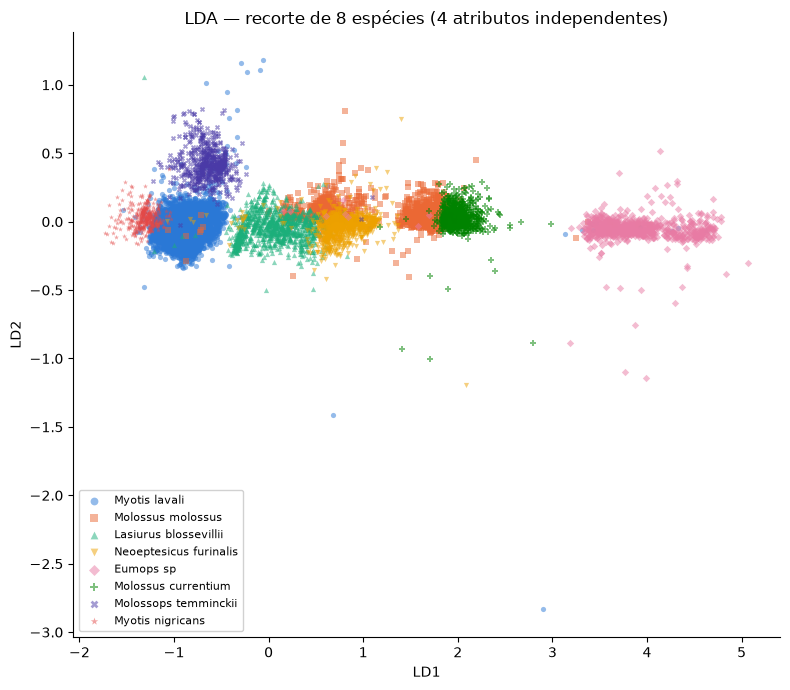

In [32]:
componentes_lda = autovetores_lda[:, :2]
X_lda = X_lda_in @ componentes_lda

fig, ax = plt.subplots(figsize=(8, 7))
for cor, marcador, especie in zip(PALETA, MARCADORES, especies_recorte):
    mask = rotulos == especie
    ax.scatter(X_lda[mask, 0], X_lda[mask, 1], s=14, alpha=0.5, color=cor,
               marker=marcador, label=especie.replace("_", " "), linewidths=0)

ax.set_xlabel("LD1")
ax.set_ylabel("LD2")
ax.set_title("LDA — recorte de 8 espécies (4 atributos independentes)")
ax.legend(fontsize=8, markerscale=1.5, framealpha=0.9)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()